# Forest fire map: FIRMS fire alerts and fire count grid

Step 3 of the tutorial, see the README. Run `job.firms` (step 1) and `job.firms_grid` (step 2) first, this notebook reads their files in `output/`.

The area of interest (AOI) is set in `.env`: the GADM provinces in `PROVINCES` of the country `COUNTRY`, Kalimantan Tengah (Indonesia) in the example, the same as the jobs. The notebook plots:

1. the provinces on a basemap,
2. the FIRMS fire alerts (VIIRS and MODIS, clipped to each province) with the 2020 forest and the large cities,
3. the fire count grid (number of alerts per cell of about 1 km, with sea, outside the AOI and WorldCover water masked),
4. the number of alerts per regency or city (GADM admin level 2), in total and per 100 km².

All boundaries are GADM 4.1, free for non-commercial use only (https://gadm.org/license.html), cached in `output/gadm/` by the jobs. The forest and cities are read from their public sources, no credential is needed. Everything is written to this computer, the figures go to `output/figures/`.

In [34]:
import os

# Run from the repository root, also when the notebook is opened from notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds
from rasterio.windows import from_bounds as window_from_bounds

from forest_fire.aoi import read_adm2, read_provinces
from forest_fire.config import AOI_NAME, AOI_TITLE, COUNTRY, DATE_NAME, FIGURE_DIR, FIRMS_DIR, FIRMS_GRID_DIR

# Lower resolution figures, keeps the notebook small
plt.rcParams["figure.dpi"] = 60
# Base text size, every other size in the plots is relative to it ("small", "large", ...)
plt.rcParams["font.size"] = 14

# The AOI of .env (AOI_TITLE), one row of maps in every figure. The figure helpers work per
# area, so several AOIs could be shown as several rows
AREAS = [AOI_TITLE]
# Name of the GADM admin level 2 units in the titles, regencies and cities (kabupaten and kota) in Indonesia
ADM2_UNIT = "regency or city"
# JRC Global Forest Cover 2020 v4, one Cloud Optimised GeoTIFF of the world at 10 m, 1 is forest
JRC_GFC_URL = "/vsicurl/https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/FOREST/GFC2020/LATEST/single-cog/JRC_GFC2020_V4_COG.tif"
# Natural Earth populated places, public domain
PLACES_URL = "/vsizip//vsicurl/https://naciscdn.org/naturalearth/10m/cultural/ne_10m_populated_places.zip/ne_10m_populated_places.shp"
# Populated places shown on the maps
MIN_POPULATION = 100_000
# Width of one subplot in inches, the height follows the shape of the area. Narrower maps keep
# the text readable when the figure is shrunk to fit a page or a post
MAP_WIDTH = 14
print(f"{AOI_TITLE} ({COUNTRY}), period {DATE_NAME}")

Kalimantan Tengah (IDN), period 2026-08-01_2026-10-31


## Map helpers

In [35]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize="small")
    # The ticks already say °E and °N, axis titles only take space between the maps
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(color="grey", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize="large",
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (500, 200, 100, 50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize="small",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize="small")


def padded_bounds(gdf, pad_frac=0.03):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = pad_frac * max(xmax - xmin, ymax - ymin)
    return xmin - pad, ymin - pad, xmax + pad, ymax + pad


def set_extent(ax, gdf):
    xmin, ymin, xmax, ymax = padded_bounds(gdf)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    # Degrees drawn equal, the axes box from area_figure has the same shape so it is filled
    ax.set_aspect("equal")


def add_basemap(ax, zoom_offset=1, **kwargs):
    # Light hillshade, one zoom level more detailed than contextily picks for the map extent (axes in degrees)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    zoom = cx.tile._calculate_zoom(xmin, ymin, xmax, ymax) + zoom_offset
    cx.add_basemap(
        ax, crs="EPSG:4326", source=cx.providers.Esri.WorldShadedRelief, zoom=zoom, attribution_size=10, **kwargs
    )


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)


def area_figure(ncols=1, map_width=MAP_WIDTH, colorbar=None):
    """One row of maps per area, placed exactly so the gap between areas stays small.

    Each map box has the shape of its area, so nothing is left empty around it. ``colorbar``
    adds color bar axes: ``"shared"`` one for the figure, ``"each"`` one next to each map.
    Returns the figure, the maps per area and the color bar axes (one, per area or None).
    """
    # Space in inches for titles, tick labels and color bars, larger with the text size
    scale = plt.rcParams["font.size"] / 10
    left, right, top, bottom, row_gap, col_gap = (v * scale for v in (0.75, 0.3, 0.45, 0.3, 0.1, 1.0))
    cbar_width, cbar_pad, cbar_label = (v * scale for v in (0.25, 0.2, 0.9))
    cbar_space = cbar_pad + cbar_width + cbar_label
    # Color bars a little away from the maps, city labels near the right edge stay readable
    each = cbar_space + 2 * cbar_pad if colorbar == "each" else 0
    shared = cbar_space + 2 * cbar_pad if colorbar == "shared" else 0

    heights = []
    for area in AREAS:
        xmin, ymin, xmax, ymax = padded_bounds(provinces[area])
        heights.append(map_width * (ymax - ymin) / (xmax - xmin))
    width = left + ncols * (map_width + each) + (ncols - 1) * col_gap + shared + right
    height = sum(top + h + bottom for h in heights) + (len(heights) - 1) * row_gap
    fig = plt.figure(figsize=(width, height))

    def rect(x, y, w, h):
        # Inches from the top left corner to a figure fraction rectangle
        return [x / width, (height - y - h) / height, w / width, h / height]

    axes, caxes = {}, {}
    y = 0
    for area, h in zip(AREAS, heights):
        y += top
        axes[area], caxes[area] = [], []
        for col in range(ncols):
            x = left + col * (map_width + each + col_gap)
            axes[area].append(fig.add_axes(rect(x, y, map_width, h)))
            if colorbar == "each":
                caxes[area].append(fig.add_axes(rect(x + map_width + 3 * cbar_pad, y + 0.15 * h, cbar_width, 0.7 * h)))
        y += h + bottom + row_gap

    if colorbar == "shared":
        x = left + ncols * map_width + (ncols - 1) * col_gap + 3 * cbar_pad
        caxes = fig.add_axes(rect(x, 0.25 * height, cbar_width, 0.5 * height))
    elif colorbar is None:
        caxes = None
    return fig, axes, caxes


def period_title(title):
    return f"{title} {DATE_NAME.replace('_', ' to ')}"

## 1. Provinces

The GADM level 1 provinces in `PROVINCES` of `.env`, each dissolved into one shape, with the cities of Natural Earth above `MIN_POPULATION` people (`POP_MAX`, the metropolitan estimate of the dataset) within the map, also outside the AOI for orientation. Kalimantan Tengah in the example.

In [36]:
provinces = {AOI_TITLE: read_provinces()}
provinces[AOI_TITLE].drop(columns="geometry")

,name
province,
kalimantan_tengah,Kalimantan Tengah


In [37]:
# Large cities, shown on every map for orientation
CITY_STYLE = dict(marker="s", size=90, face="white", edge="black")


# Natural Earth has a few places sharing the name and population of another one,
# so the population can't be trusted for either
places_table = gpd.read_file(PLACES_URL, columns=["NAME", "POP_MAX"], ignore_geometry=True)
ambiguous = set(
    places_table[places_table.duplicated(["NAME", "POP_MAX"], keep=False)][["NAME", "POP_MAX"]].itertuples(index=False)
)
print(f"{len(ambiguous)} name and population pairs shared by several places left out")


def read_cities(gdf):
    # Large cities within the map, also outside the area for orientation
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = 0.03 * max(xmax - xmin, ymax - ymin)
    places = gpd.read_file(
        PLACES_URL, bbox=(xmin - pad, ymin - pad, xmax + pad, ymax + pad), columns=["NAME", "ADM0NAME", "POP_MAX"]
    )
    places = places[places["POP_MAX"] > MIN_POPULATION].sort_values("POP_MAX", ascending=False)
    # A boolean Series, a plain list would select columns when there is no city
    places = places[pd.Series([(name, pop) not in ambiguous for name, pop in zip(places["NAME"], places["POP_MAX"])], index=places.index, dtype=bool)]
    # Drop cities within 0.5 degree (about 55 km) of a larger one, Bekasi is part of Greater Jakarta
    kept = []
    for index, city in places.iterrows():
        if all(city.geometry.distance(places.loc[other].geometry) > 0.5 for other in kept):
            kept.append(index)
    return places.loc[kept]


cities = {area: read_cities(provinces[area]) for area in AREAS}


def add_cities(ax, area, zorder=6):
    ax.scatter(
        cities[area].geometry.x,
        cities[area].geometry.y,
        s=CITY_STYLE["size"],
        marker=CITY_STYLE["marker"],
        facecolor=CITY_STYLE["face"],
        edgecolor=CITY_STYLE["edge"],
        linewidths=1.2,
        zorder=zorder,
    )
    for _, city in cities[area].iterrows():
        ax.annotate(
            city["NAME"],
            (city.geometry.x, city.geometry.y),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize="small",
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
            zorder=zorder,
        )


CITY_HANDLE = Line2D(
    [],
    [],
    linestyle="none",
    marker=CITY_STYLE["marker"],
    markersize=10,
    markerfacecolor=CITY_STYLE["face"],
    markeredgecolor=CITY_STYLE["edge"],
    label=f"City above {MIN_POPULATION:,} people (Natural Earth)",
)
LEGEND = dict(loc="upper right", bbox_to_anchor=(0.9, 1), fontsize="small")

pd.concat({area: gdf.drop(columns="geometry") for area, gdf in cities.items()})

14 name and population pairs shared by several places left out


NAME   ADM0NAME  POP_MAX
Kalimantan Tengah 4  Bandjarmasin  Indonesia   603576
                  2  Palangkaraya  Indonesia   148289

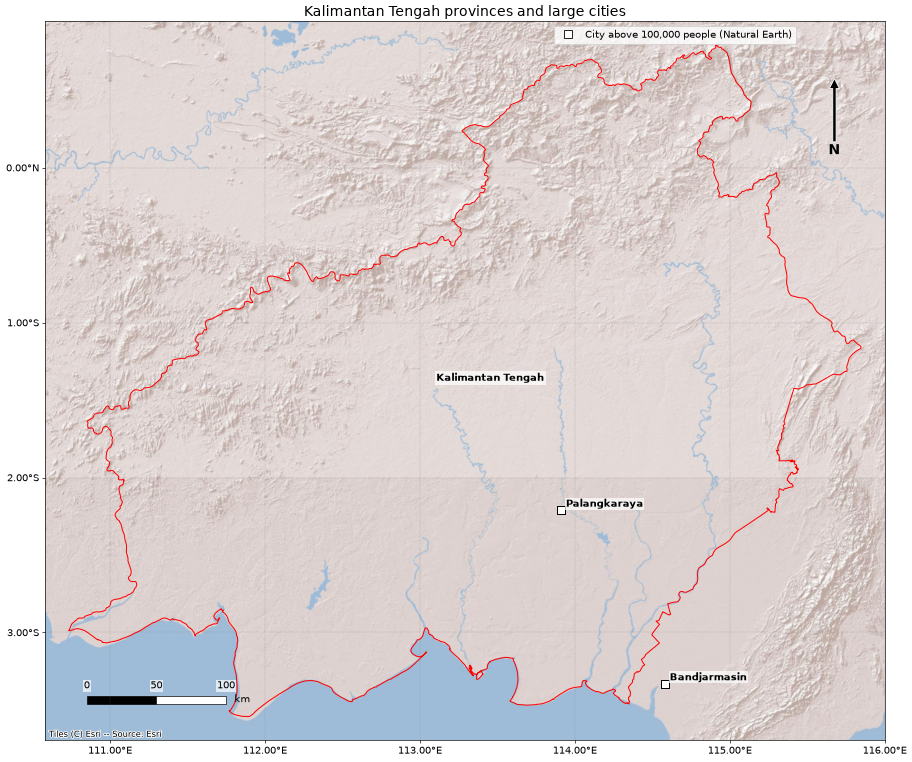

In [38]:
fig, axes, _ = area_figure()

for area, (ax,) in axes.items():
    provinces[area].boundary.plot(ax=ax, color="red", linewidth=1.2)
    add_cities(ax, area)
    for _, row in provinces[area].iterrows():
        point = row.geometry.representative_point()
        ax.text(
            point.x,
            point.y,
            row["name"],
            ha="center",
            fontsize="small",
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2),
        )

    set_extent(ax, provinces[area])
    add_basemap(ax)
    decorate(ax, f"{area} provinces and large cities")
    ax.legend(handles=[CITY_HANDLE], **LEGEND)

plt.show()

## 2. FIRMS fire alerts, forest and large cities

All alerts from the province files. Each point is the centre of a satellite pixel with an active fire detection (375 m for VIIRS, 1 km for MODIS), not a burned area. MODIS near real time has no data for early August, so MODIS points cover only part of the period.

Forest is the JRC Global Forest Cover 2020 v4 (European Commission, CC BY 4.0), read straight from its global 10 m Cloud Optimised GeoTIFF at about 1 km with the most common class per cell, which is enough at this map scale, and clipped to the provinces. Only the overview close to 1 km is downloaded, a few tens of MB per region. Forest in 2020 does not mean forest during the 2026 fires. The cities are the same as in the map above.

In [39]:
# One file per province or state from job.firms
firms = {
    area: gpd.GeoDataFrame(
        pd.concat(
            [
                gpd.read_file(
                    FIRMS_DIR / f"{province}_{DATE_NAME}.fgb", columns=["acq_date", "instrument", "satellite"]
                ).assign(province=province)
                for province in provinces[area].index
            ],
            ignore_index=True,
        ),
        crs="EPSG:4326",
    )
    for area in AREAS
}

for area, alerts in firms.items():
    print(f"{area}: {len(alerts):,} alerts, {alerts['acq_date'].min()} to {alerts['acq_date'].max()}")
pd.concat({area: alerts.groupby(["province", "instrument"]).size().unstack(fill_value=0) for area, alerts in firms.items()})

Kalimantan Tengah: 536,563 alerts, 2026-08-01 to 2026-10-31


,instrument,MODIS,VIIRS
,province,,
Kalimantan Tengah,kalimantan_tengah,29062,507501


In [40]:
# Forest read at about 1 km, the same cell size as the fire count grid
FOREST_RESOLUTION = 0.009


def read_forest(gdf):
    """Forest 2020 of the polygons of gdf as a boolean array and its extent for imshow."""
    xmin, ymin, xmax, ymax = gdf.total_bounds
    shape = (round((ymax - ymin) / FOREST_RESOLUTION), round((xmax - xmin) / FOREST_RESOLUTION))
    with rasterio.open(JRC_GFC_URL) as src:
        # GDAL reads the overview closest to the output shape, the most common class per cell
        gfc = src.read(
            1, window=window_from_bounds(xmin, ymin, xmax, ymax, src.transform), out_shape=shape, resampling=Resampling.mode
        )
    # Forest only inside the provinces, not in Malaysia, Brunei or the other islands
    inside = geometry_mask(gdf.geometry, out_shape=shape, transform=from_bounds(xmin, ymin, xmax, ymax, shape[1], shape[0]), invert=True)
    return (gfc == 1) & inside, (xmin, xmax, ymin, ymax)


forest_layers = {}
for area in AREAS:
    forest_layers[area] = [read_forest(provinces[area])]
    cells = sum(int(forest.sum()) for forest, _ in forest_layers[area])
    print(f"{area}: {cells:,} forest cells of about 1 km")

Kalimantan Tengah: 111,488 forest cells of about 1 km


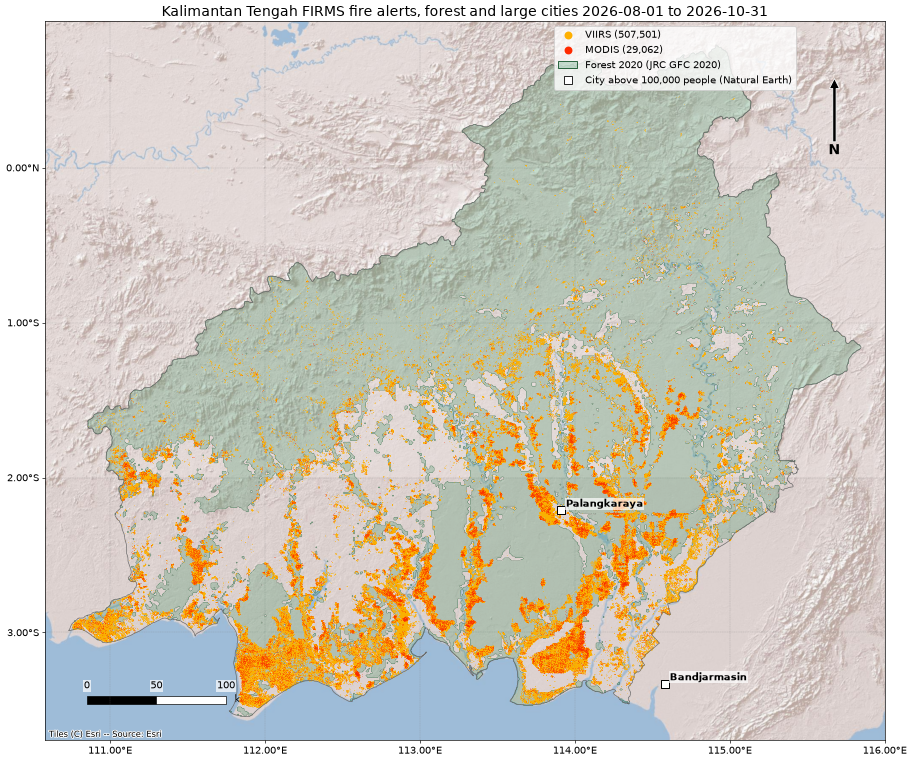

In [41]:
INSTRUMENT_COLORS = {"VIIRS": "#ffb000", "MODIS": "#ff2a00"}
FOREST_STYLE = dict(face="#2e8b57", edge="#0b4d23", alpha=0.25)


def add_forest(ax, area, zorder=2):
    # Forest as a low opacity fill with a darker outline along its edge
    for forest, extent in forest_layers[area]:
        ax.imshow(
            np.ma.masked_where(~forest, forest),
            extent=extent,
            cmap=ListedColormap([FOREST_STYLE["face"]]),
            alpha=FOREST_STYLE["alpha"],
            interpolation="nearest",
            zorder=zorder,
        )
        ax.contour(
            forest.astype("uint8"),
            levels=[0.5],
            extent=extent,
            origin="upper",
            colors=FOREST_STYLE["edge"],
            linewidths=0.3,
            zorder=zorder,
        )


FOREST_HANDLE = Patch(
    facecolor=FOREST_STYLE["face"] + "40", edgecolor=FOREST_STYLE["edge"], label="Forest 2020 (JRC GFC 2020)"
)

fig, axes, _ = area_figure()

for area, (ax,) in axes.items():
    add_forest(ax, area)
    # Scatter on the raw coordinates, much faster than GeoDataFrame.plot for millions of points
    for instrument, color in INSTRUMENT_COLORS.items():
        points = firms[area][firms[area]["instrument"] == instrument]
        ax.scatter(
            points.geometry.x,
            points.geometry.y,
            s=0.3,
            color=color,
            linewidths=0,
            label=f"{instrument} ({len(points):,})",
            rasterized=True,
            zorder=4,
        )
    provinces[area].boundary.plot(ax=ax, color="dimgrey", linewidth=0.8, zorder=5)
    add_cities(ax, area)

    set_extent(ax, provinces[area])
    add_basemap(ax, zorder=1)
    decorate(ax, period_title(f"{area} FIRMS fire alerts, forest and large cities"))

    handles, _ = ax.get_legend_handles_labels()
    legend = ax.legend(handles=handles + [FOREST_HANDLE, CITY_HANDLE], **LEGEND)
    # The alert points are tiny on the map, larger in the legend so their color can be read
    for handle in legend.legend_handles[: len(INSTRUMENT_COLORS)]:
        handle.set_sizes([90])

plt.show()

## 3. Fire count grid

Number of FIRMS alerts per grid cell (0.009°, about 1 km) from `job.firms_grid` (step 2) for the whole AOI. The grid count only includes alerts within half a cell from the cell centre, so it counts fewer alerts than the points above. Cells with no alerts (0) are shown as no data, as are the masked sea, outside the area and WorldCover water cells. Log color scale because a few cells have far more alerts than the rest. The 2020 forest and the large cities are drawn as in the map above.

In [42]:
grids = {}
for area in AREAS:
    with rasterio.open(FIRMS_GRID_DIR / f"{AOI_NAME}_{DATE_NAME}.tif") as src:
        grid = src.read(1)
        bounds = src.bounds
        nodata = src.nodata
        resolution = src.res

    # Masked cells and cells without alerts are not shown
    fire_count = np.ma.masked_where((grid == nodata) | (grid == 0), grid)
    grids[area] = [(fire_count, (bounds.left, bounds.right, bounds.bottom, bounds.top))]

    print(
        f"{area}: cell size {resolution[0]:.4f}°, {fire_count.count():,} cells with alerts, "
        f"{int(fire_count.sum()):,} alerts counted, max {fire_count.max()} per cell"
    )

grid_max = max(fire_count.max() for layers in grids.values() for fire_count, _ in layers)

Kalimantan Tengah: cell size 0.0090°, 31,583 cells with alerts, 420,834 alerts counted, max 297 per cell


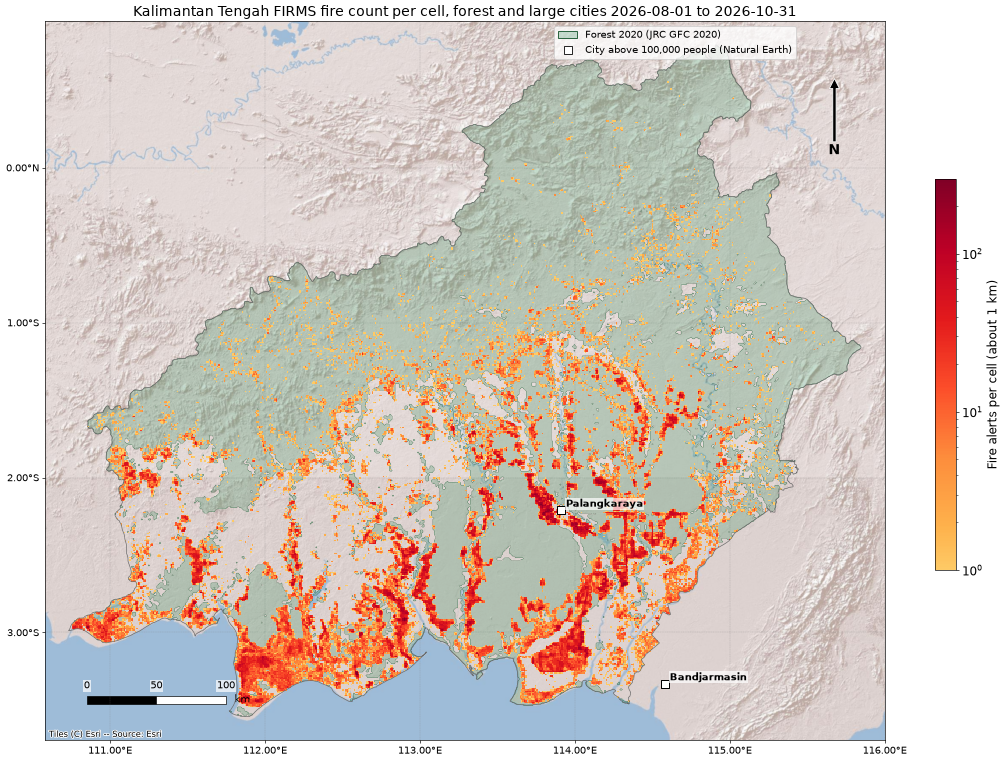

In [43]:
# YlOrRd without its near white start, so cells with few alerts stay visible on the light basemap
grid_cmap = ListedColormap(plt.get_cmap("YlOrRd")(np.linspace(0.3, 1, 256)))
grid_norm = LogNorm(vmin=1, vmax=grid_max)

fig, axes, cax = area_figure(colorbar="shared")

for area, (ax,) in axes.items():
    add_forest(ax, area, zorder=2)
    for fire_count, extent in grids[area]:
        image = ax.imshow(fire_count, extent=extent, cmap=grid_cmap, norm=grid_norm, interpolation="nearest", zorder=3)
    provinces[area].boundary.plot(ax=ax, color="dimgrey", linewidth=0.8, zorder=4)
    add_cities(ax, area)

    set_extent(ax, provinces[area])
    add_basemap(ax, zorder=1)
    decorate(ax, period_title(f"{area} FIRMS fire count per cell, forest and large cities"))
    ax.legend(handles=[FOREST_HANDLE, CITY_HANDLE], **LEGEND)

# One color bar for the map
fig.colorbar(image, cax=cax, label="Fire alerts per cell (about 1 km)")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / f"fire_count_per_cell_{DATE_NAME}.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Fire alerts per regency and city

GADM level 2 units of the AOI provinces: regencies and cities (kabupaten and kota) in Indonesia. Each FIRMS alert is assigned to the unit it falls in, so every alert is counted, unlike the grid above. The units differ a lot in size, so the alerts per 100 km² are shown in a second figure after the total count, with the area computed in an equal area projection (EPSG:6933).

In [44]:
units = {}
for area in AREAS:
    gdf = read_adm2()

    alerts = firms[area][["instrument", "geometry"]].sjoin(gdf[["id", "geometry"]], predicate="within")
    # Both columns also when an instrument has no alert in the period
    counts = alerts.groupby(["id", "instrument"]).size().unstack(fill_value=0).reindex(columns=["VIIRS", "MODIS"], fill_value=0)
    gdf = gdf.merge(counts, left_on="id", right_index=True, how="left")
    gdf[["VIIRS", "MODIS"]] = gdf[["VIIRS", "MODIS"]].fillna(0).astype(int)
    gdf["alerts"] = gdf["VIIRS"] + gdf["MODIS"]
    gdf["area_km2"] = gdf.to_crs("EPSG:6933").area / 1e6
    gdf["alerts_per_100km2"] = gdf["alerts"] / gdf["area_km2"] * 100
    units[area] = gdf

    # Alerts near the coast or on borders can fall outside every admin level 2 polygon
    print(f"{area}: {len(gdf)} units, {gdf['alerts'].sum():,} of {len(firms[area]):,} alerts assigned")

pd.concat(
    {
        area: gdf.sort_values("alerts", ascending=False)[
            ["name", "type", "province", "VIIRS", "MODIS", "alerts", "area_km2", "alerts_per_100km2"]
        ]
        .head(10)
        .round(1)
        .reset_index(drop=True)
        for area, gdf in units.items()
    }
)

Kalimantan Tengah: 14 units, 536,563 of 536,563 alerts assigned


name       type           province  VIIRS  \
Kalimantan Tengah 0        Pulang Pisau  Kabupaten  Kalimantan Tengah  96273   
                  1             Seruyan  Kabupaten  Kalimantan Tengah  77256   
                  2              Kapuas  Kabupaten  Kalimantan Tengah  75048   
                  3  Kotawaringin Timur  Kabupaten  Kalimantan Tengah  69361   
                  4            Katingan  Kabupaten  Kalimantan Tengah  48972   
                  5       Palangka Raya       Kota  Kalimantan Tengah  45046   
                  6  Kotawaringin Barat  Kabupaten  Kalimantan Tengah  38051   
                  7            Sukamara  Kabupaten  Kalimantan Tengah  15835   
                  8      Barito Selatan  Kabupaten  Kalimantan Tengah  14601   
                  9            Lamandau  Kabupaten  Kalimantan Tengah  11853   

                     MODIS  alerts  area_km2  alerts_per_100km2  
Kalimantan Tengah 0   6002  102275    9722.4             1052.0  
                  1   4603   81859   16635.5              492.1  
                  2   4083   79131   17295.0              457.5  
                  3   3727   73088   15698.7              465.6  
                  4   3081   52053   19418.4              268.1  
                  5   1691   46737    2602.3             1796.0  
                  6   2409   40460    8386.7              482.4  
                  7    831   16666    3284.9              507.3  
                  8    851   15452    6403.4              241.3  
                  9    947   12800    7330.3              174.6

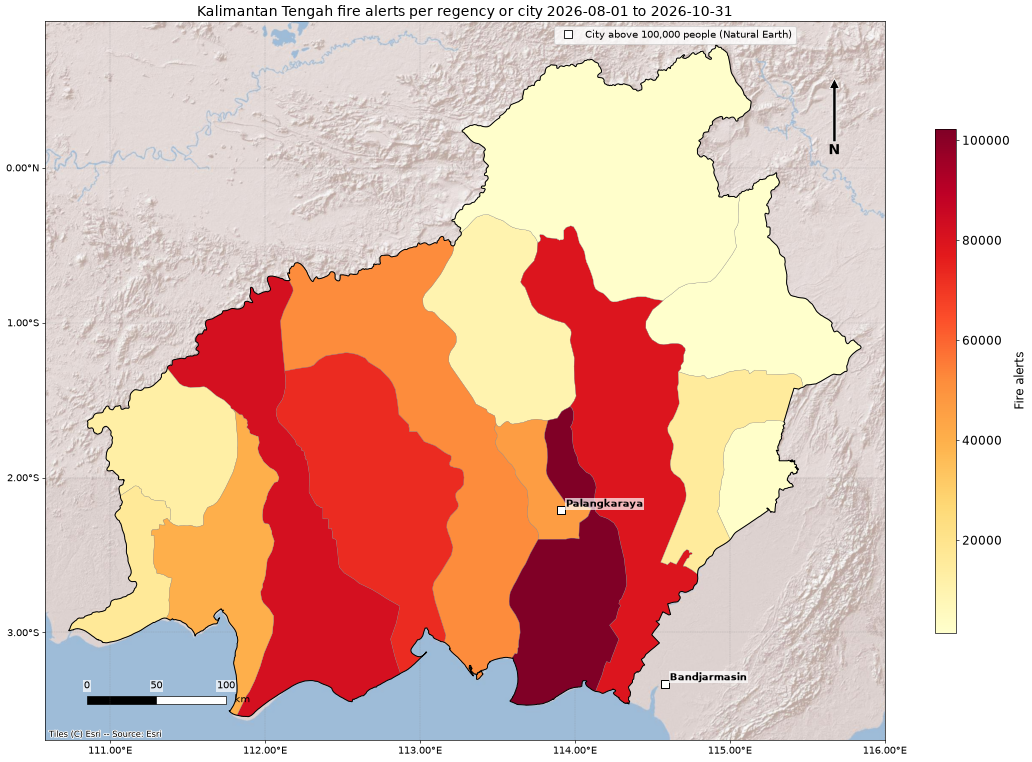

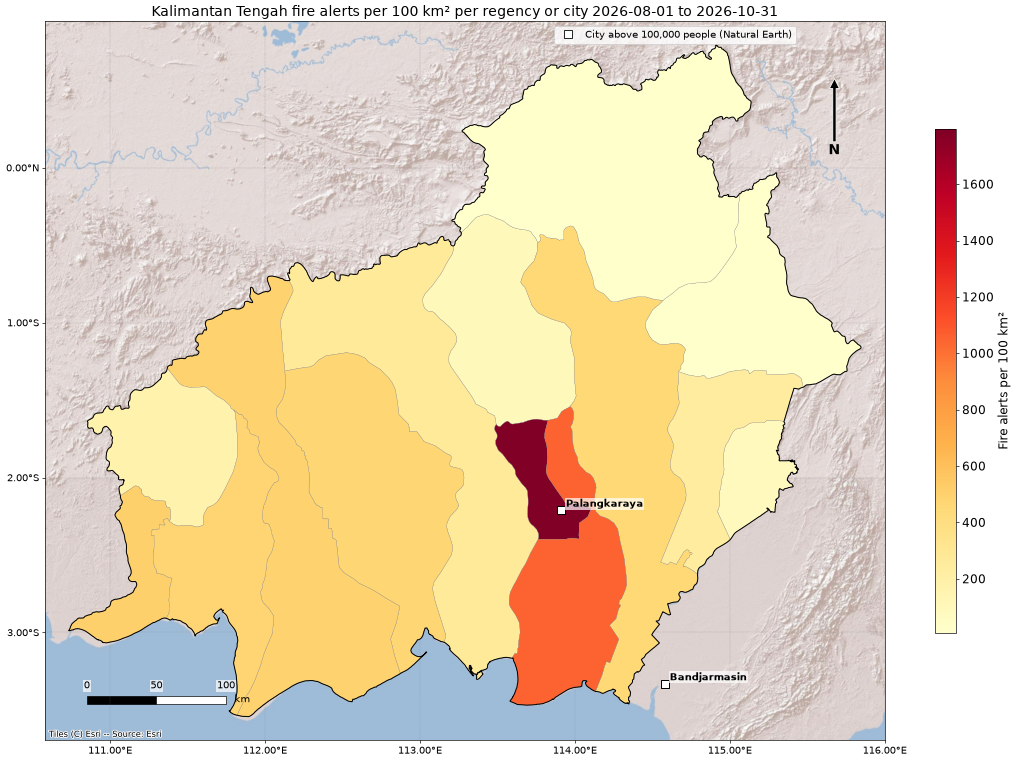

In [45]:
METRICS = {
    "alerts": "Fire alerts",
    "alerts_per_100km2": "Fire alerts per 100 km²",
}

# One figure per metric, one map per area with its own color scale
for column, label in METRICS.items():
    fig, axes, caxes = area_figure(colorbar="each")
    for area, (ax,) in axes.items():
        unit = ADM2_UNIT
        units[area].plot(
            ax=ax,
            column=column,
            cmap="YlOrRd",
            edgecolor="grey",
            linewidth=0.3,
            legend=True,
            cax=caxes[area][0],
            legend_kwds=dict(label=label),
            zorder=2,
        )
        provinces[area].boundary.plot(ax=ax, color="black", linewidth=1.2, zorder=3)
        add_cities(ax, area)

        set_extent(ax, provinces[area])
        add_basemap(ax, zorder=1)
        decorate(ax, period_title(f"{area} {label.lower()} per {unit}"))
        # Only the city marker, the unit colors are explained by the color bar
        ax.legend(handles=[CITY_HANDLE], **LEGEND)

    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / f"{column}_per_adm2_{DATE_NAME}.png", dpi=150, bbox_inches="tight")
    plt.show()